# E-commerce Customer Behaviour Analytics
**HCLTech Career Shaper Programme · III Year Industry Project (No. 51) · 2025-26**

Deep EDA of e-commerce clickstream sessions to understand user journeys, funnel drop-off points and purchase drivers.

**Notebook flow:** 1) Data understanding → 2) Cleaning & validation → 3) Funnel & behavioural EDA (7 figures) → 4) Statistical testing → 5) SQL view → 6) Predictive check → 7) Conclusions

In [1]:
import json, sqlite3, warnings, hashlib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportion_confint
warnings.filterwarnings('ignore')

import os
SRC  = 'dataset.csv'      # keep dataset.csv in the same folder as this notebook
OUT  = '.'
FIGS = OUT + '/figs'
os.makedirs(FIGS, exist_ok=True)
sns.set_theme(style='whitegrid', context='notebook')
PAL = {'blue':'#1F4E79','teal':'#2A9D8F','amber':'#E9A23B','red':'#C8553D','grey':'#8D99AE'}
R = {}   # results store, reused by the report

## 1. Data understanding

In [2]:
df = pd.read_csv(SRC)
print('Shape:', df.shape)
display(df.head(8))
print(); print(df.dtypes)

Shape: (500, 8)


,session_id,user_id,page_type,product_id,time_on_page_s,add_to_cart,purchased,device_type
0,SES00001,U09458,Category,P0224,243,0,0,Mobile
1,SES00002,U09200,Home,P0013,67,0,1,Tablet
2,SES00003,U07053,Home,P0169,21,0,0,Desktop
3,SES00004,U06094,Product,P0358,286,1,0,Tablet
4,SES00005,U07857,Category,P0157,195,0,1,Tablet
5,SES00006,U05073,Category,P0448,174,1,0,Tablet
6,SES00007,U05700,Product,P0459,59,0,0,Mobile
7,SES00008,U00710,Confirmation,P0241,32,0,0,Mobile



session_id          str
user_id             str
page_type           str
product_id          str
time_on_page_s    int64
add_to_cart       int64
purchased         int64
device_type         str
dtype: object


In [3]:
print('Missing values per column:'); print(df.isna().sum().to_string())
print('\nExact duplicate rows :', df.duplicated().sum())
print('Duplicate session_id  :', df.session_id.duplicated().sum())
print('Unique users / products:', df.user_id.nunique(), '/', df.product_id.nunique())
print('ID formats valid      :', df.session_id.str.fullmatch(r'SES\d{5}').all(),
      df.user_id.str.fullmatch(r'U\d{5}').all(), df.product_id.str.fullmatch(r'P\d{4}').all())
print('Binary columns clean  :', set(df.add_to_cart.unique())<= {0,1}, set(df.purchased.unique())<= {0,1})
print('time_on_page_s range  :', df.time_on_page_s.min(), '-', df.time_on_page_s.max())
q1,q3 = df.time_on_page_s.quantile([.25,.75]); iqr=q3-q1
print('IQR outliers in time  :', ((df.time_on_page_s<q1-1.5*iqr)|(df.time_on_page_s>q3+1.5*iqr)).sum())
R.update(rows=len(df), cols=df.shape[1], users=int(df.user_id.nunique()), products=int(df.product_id.nunique()),
         repeat_users=int((df.user_id.value_counts()>1).sum()))
display(df.describe(include='all').T)

Missing values per column:
session_id        0
user_id           0
page_type         0
product_id        0
time_on_page_s    0
add_to_cart       0
purchased         0
device_type       0

Exact duplicate rows : 0
Duplicate session_id  : 0
Unique users / products: 490 / 307
ID formats valid      : True True True
Binary columns clean  : True True
time_on_page_s range  : 5 - 300
IQR outliers in time  : 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
session_id,500,500,SES00001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
user_id,500,490,U06090,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
page_type,500,6,Category,96,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_id,500,307,P0448,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
time_on_page_s,500.0,NaN,NaN,NaN,149.976,85.824443,5.0,77.75,147.5,223.0,300.0
add_to_cart,500.0,NaN,NaN,NaN,0.35,0.477447,0.0,0.0,0.0,1.0,1.0
purchased,500.0,NaN,NaN,NaN,0.212,0.409134,0.0,0.0,0.0,0.0,1.0
device_type,500,3,Tablet,171,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Cleaning & validation
No nulls, duplicates or malformed IDs exist, so the structural clean-up is light (trim/standardise text, enforce types, ordered categories).  
The **logic validation** is where the real findings are: each row is one session, so `purchased=1` should imply `add_to_cart=1`, and a `Confirmation` page should imply a purchase. Violations are **flagged, not deleted**, so they stay traceable and the treatment can be agreed with the data owner.

**Privacy (DPDP Act 2023):** `user_id` is already a pseudonymous token (`U#####`) with no names/emails/IPs. We additionally add a salted SHA-256 `user_key` for any downstream joins so the raw token is not needed.

In [4]:
d = df.copy()
for c in ['session_id','user_id','product_id','page_type','device_type']:
    d[c] = d[c].astype(str).str.strip()
d['page_type']   = pd.Categorical(d.page_type, ['Home','Category','Product','Cart','Checkout','Confirmation'], ordered=True)
d['device_type'] = d.device_type.str.title().astype('category')
d[['add_to_cart','purchased']] = d[['add_to_cart','purchased']].astype('int8')

# --- logic flags (kept, not dropped)
d['flag_purchase_without_cart']     = ((d.purchased==1)&(d.add_to_cart==0)).astype('int8')
d['flag_confirmation_no_purchase']  = ((d.page_type=='Confirmation')&(d.purchased==0)).astype('int8')
d['flag_purchase_on_early_page']    = ((d.purchased==1)&(d.page_type.isin(['Home','Category','Product']))).astype('int8')
d['flag_any_inconsistency']         = d[[c for c in d.columns if c.startswith('flag_') and c!='flag_any_inconsistency']].max(axis=1)

# --- derived features
d['time_bucket'] = pd.cut(d.time_on_page_s,[0,60,120,180,240,300],labels=['0-60s','61-120s','121-180s','181-240s','241-300s'])
d['engagement']  = pd.cut(d.time_on_page_s,[0,60,180,300],labels=['Low (<=60s)','Medium (61-180s)','High (>180s)'])
d['session_outcome'] = np.select([(d.purchased==1)&(d.add_to_cart==1),(d.purchased==1)&(d.add_to_cart==0),(d.add_to_cart==1)],
                                 ['Cart + Purchase','Purchase (no cart)','Cart abandoned'],'Browse only')
SALT = 'hcl-career-shaper-2026'   # demo salt; keep secret/rotate in production
d['user_key'] = d.user_id.map(lambda u: hashlib.sha256((SALT+u).encode()).hexdigest()[:12])

flag_cols = [c for c in d.columns if c.startswith('flag_')]
print(d[flag_cols].sum().to_string())
print('\nSessions with >=1 inconsistency: %d of %d (%.1f%%)' % (d.flag_any_inconsistency.sum(), len(d), 100*d.flag_any_inconsistency.mean()))
R.update(flag_purchase_without_cart=int(d.flag_purchase_without_cart.sum()),
         flag_confirmation_no_purchase=int(d.flag_confirmation_no_purchase.sum()),
         flag_purchase_on_early_page=int(d.flag_purchase_on_early_page.sum()),
         flag_any=int(d.flag_any_inconsistency.sum()))
d.to_csv(OUT+'/dataset_cleaned.csv', index=False)
d.head()

flag_purchase_without_cart        74
flag_confirmation_no_purchase     60
flag_purchase_on_early_page       56
flag_any_inconsistency           151

Sessions with >=1 inconsistency: 151 of 500 (30.2%)


,session_id,user_id,page_type,product_id,time_on_page_s,add_to_cart,purchased,device_type,flag_purchase_without_cart,flag_confirmation_no_purchase,flag_purchase_on_early_page,flag_any_inconsistency,time_bucket,engagement,session_outcome,user_key
0,SES00001,U09458,Category,P0224,243,0,0,Mobile,0,0,0,0,241-300s,High (>180s),Browse only,813d528817d1
1,SES00002,U09200,Home,P0013,67,0,1,Tablet,1,0,1,1,61-120s,Medium (61-180s),Purchase (no cart),cc5af78b9731
2,SES00003,U07053,Home,P0169,21,0,0,Desktop,0,0,0,0,0-60s,Low (<=60s),Browse only,48aeb731abbc
3,SES00004,U06094,Product,P0358,286,1,0,Tablet,0,0,0,0,241-300s,High (>180s),Cart abandoned,345d77631f77
4,SES00005,U07857,Category,P0157,195,0,1,Tablet,1,0,1,1,181-240s,High (>180s),Purchase (no cart),e163c6dd0e02


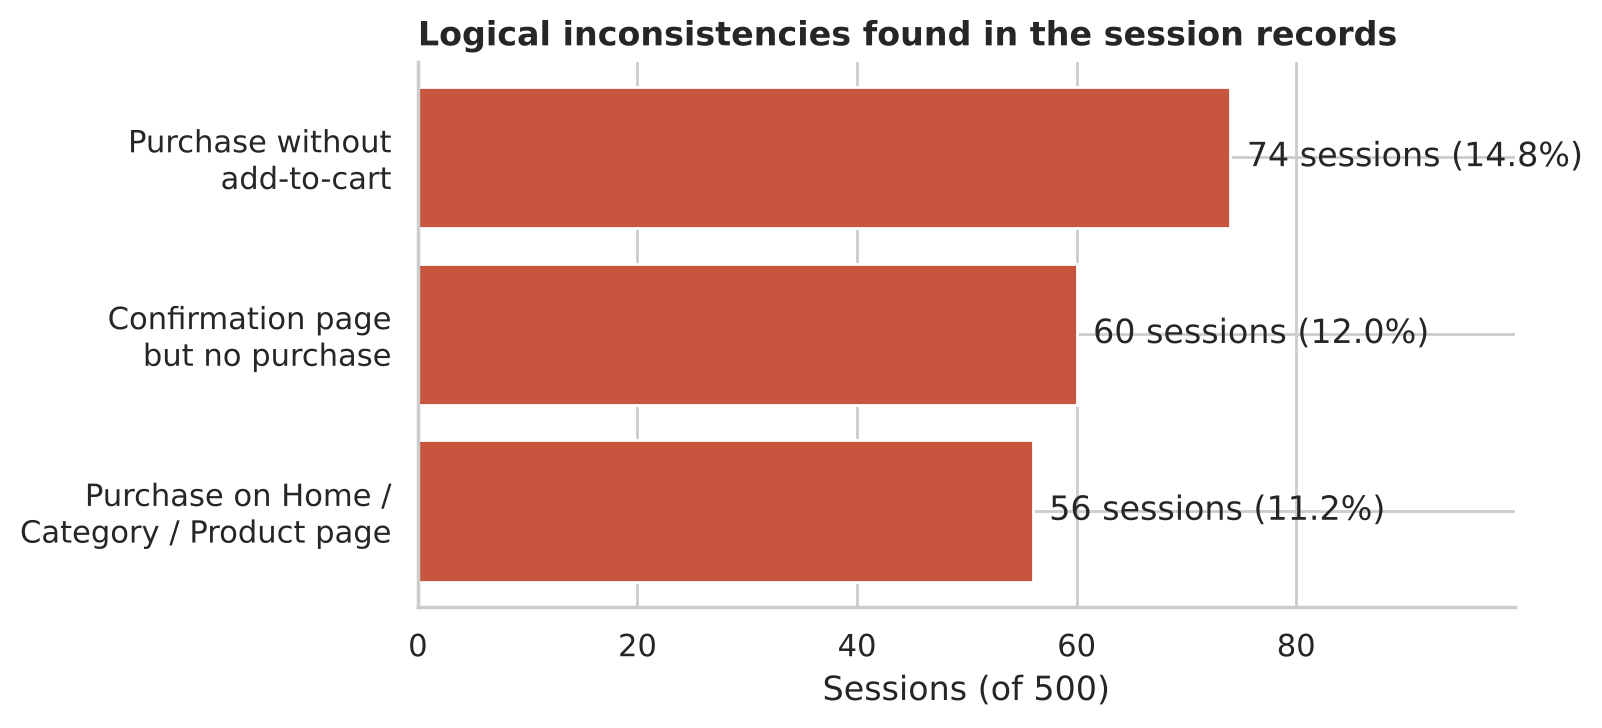

In [5]:
# Figure 1 - data-quality / logical consistency
fig, ax = plt.subplots(figsize=(8,3.8))
labs = ['Purchase without\nadd-to-cart','Confirmation page\nbut no purchase','Purchase on Home /\nCategory / Product page']
vals = [R['flag_purchase_without_cart'],R['flag_confirmation_no_purchase'],R['flag_purchase_on_early_page']]
b = ax.barh(labs, vals, color=PAL['red']); ax.invert_yaxis()
for r,v in zip(b,vals): ax.text(v+1.5, r.get_y()+r.get_height()/2, f'{v} sessions ({v/len(d):.1%})', va='center')
ax.set_xlim(0,max(vals)*1.35); ax.set_xlabel('Sessions (of 500)'); ax.set_title('Logical inconsistencies found in the session records', loc='left', fontweight='bold')
sns.despine(); plt.tight_layout(); plt.savefig(FIGS+'/fig1_data_quality.png', dpi=170); plt.show()

## 3. Funnel & behavioural EDA

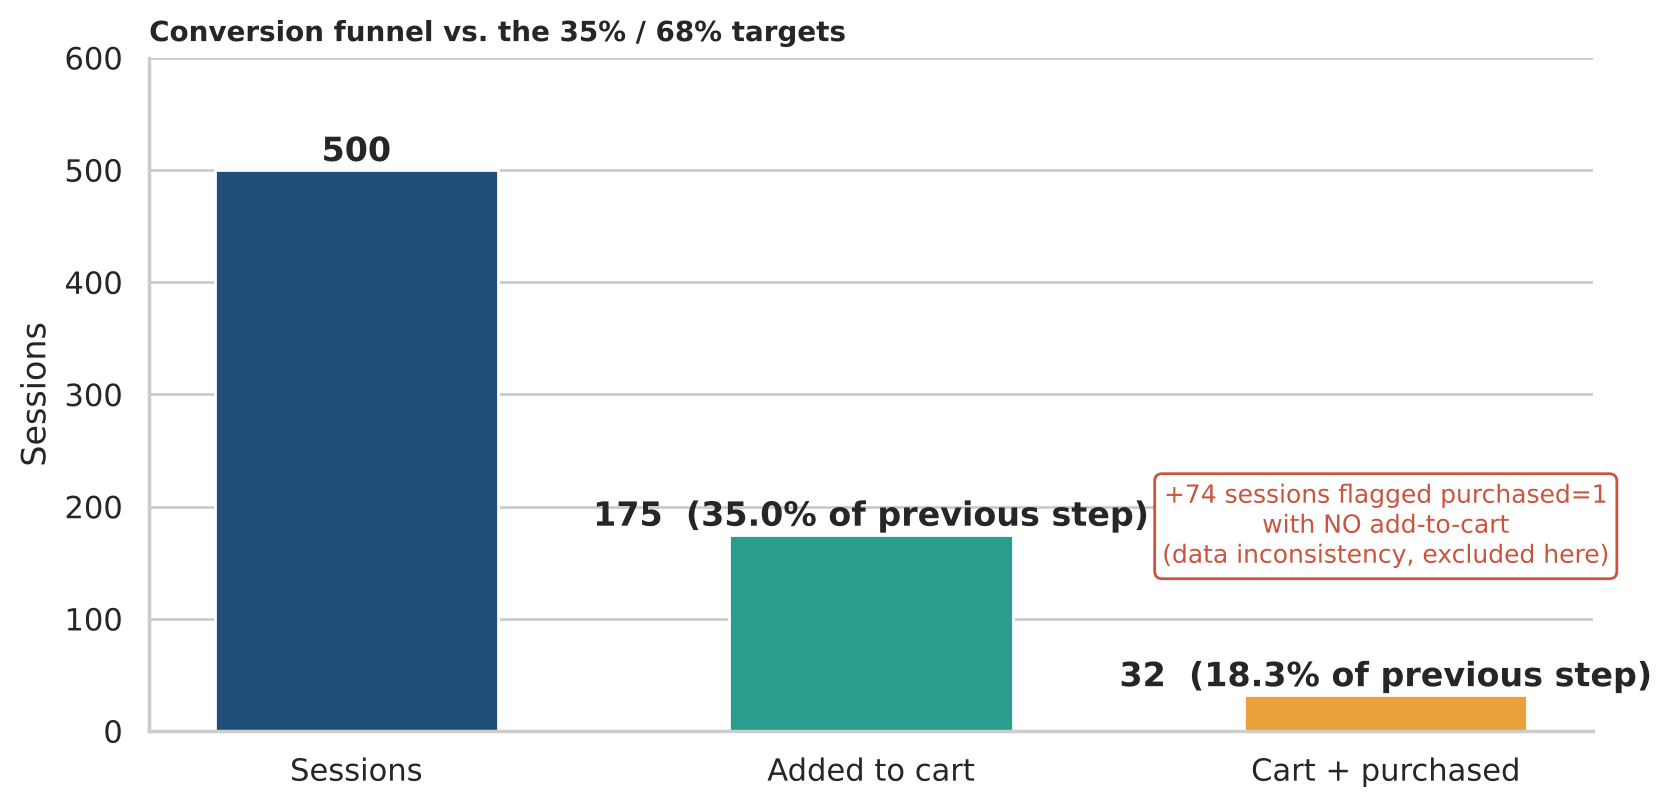

0.35 0.18285714285714286 0.212


In [6]:
# Figure 2 - funnel vs targets in the dataset-generation prompt (landing->cart 35%, cart->purchase 68%)
n=len(d); cart=int(d.add_to_cart.sum()); both=int(((d.add_to_cart==1)&(d.purchased==1)).sum()); purch=int(d.purchased.sum())
R.update(n=n, cart=cart, cart_rate=cart/n, purch=purch, purch_rate=purch/n, cart_then_purch=both, cart_to_purch=both/cart,
         purch_no_cart=purch-both, cart_abandon=cart-both, cart_abandon_rate=(cart-both)/cart)
fig, ax = plt.subplots(figsize=(8.6,4.2))
steps=['Sessions','Added to cart','Cart + purchased']; v=[n,cart,both]; cols=[PAL['blue'],PAL['teal'],PAL['amber']]
bars=ax.bar(steps,v,color=cols,width=.55)
for bar,val,prev in zip(bars,v,[None,n,cart]):
    t=f'{val}' if prev is None else f'{val}  ({val/prev:.1%} of previous step)'
    ax.text(bar.get_x()+bar.get_width()/2,val+8,t,ha='center',fontweight='bold')
ax.axhline(0,color='k',lw=.6)
ax.text(2,150,f'+{purch-both} sessions flagged purchased=1\nwith NO add-to-cart\n(data inconsistency, excluded here)',ha='center',color=PAL['red'],fontsize=9,bbox=dict(boxstyle='round',fc='white',ec=PAL['red']))
ax.grid(axis='x',visible=False)
ax.set_ylim(0,600); ax.set_ylabel('Sessions'); ax.set_title('Conversion funnel vs. the 35% / 68% targets',loc='left',fontweight='bold',fontsize=10)
sns.despine(); plt.tight_layout(); plt.savefig(FIGS+'/fig2_funnel.png',dpi=170); plt.show()
print(R['cart_rate'], R['cart_to_purch'], R['purch_rate'])

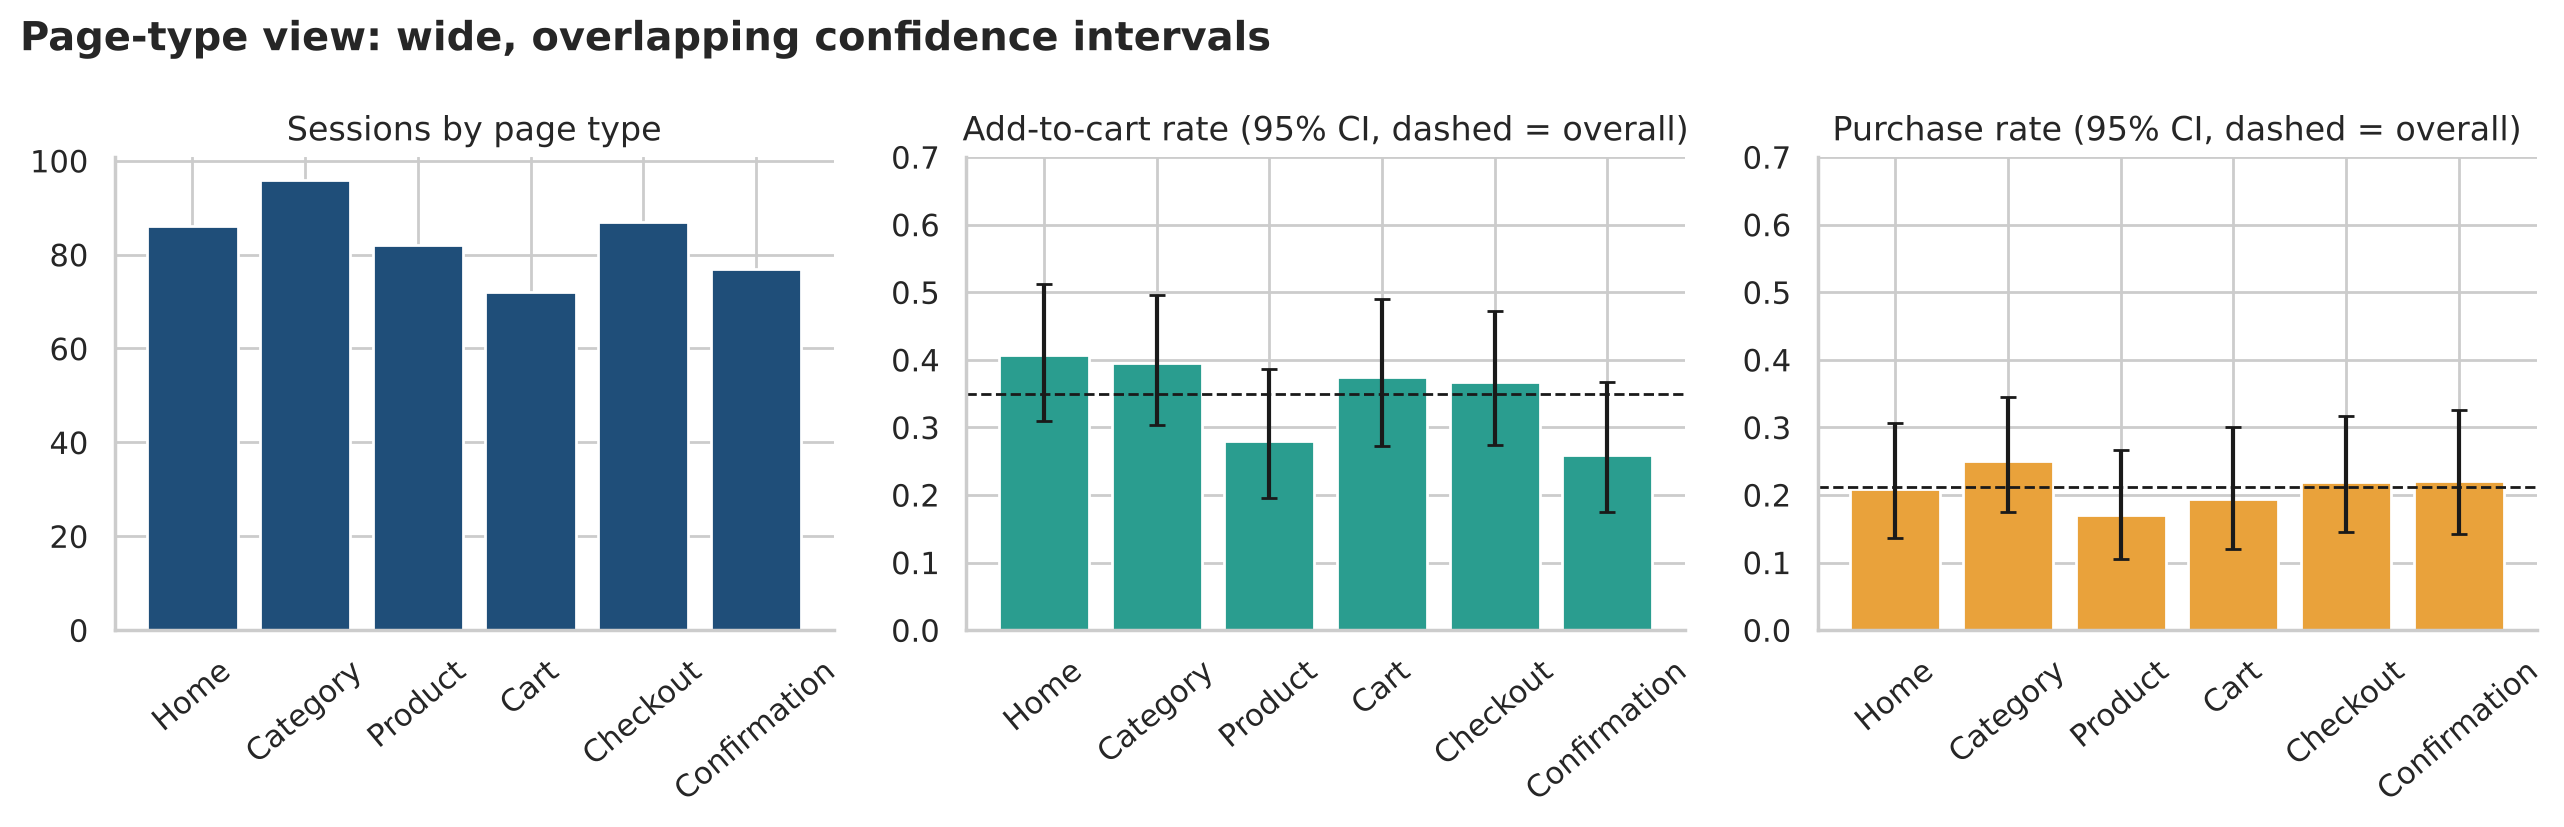

add_to_cart                     purchased                    
                    rate     lo     hi     n      rate     lo     hi     n
page_type                                                                 
Home               0.407  0.309  0.513  86.0     0.209  0.137  0.307  86.0
Category           0.396  0.304  0.496  96.0     0.250  0.174  0.345  96.0
Product            0.280  0.195  0.386  82.0     0.171  0.105  0.266  82.0
Cart               0.375  0.272  0.490  72.0     0.194  0.120  0.300  72.0
Checkout           0.368  0.274  0.473  87.0     0.218  0.145  0.316  87.0
Confirmation       0.260  0.175  0.367  77.0     0.221  0.143  0.325  77.0

In [7]:
# Figure 3 - page type: traffic share and conversion with 95% Wilson CIs
def rate_ci(g, col):
    k=g[col].sum(); m=len(g); lo,hi=proportion_confint(k,m,method='wilson'); return pd.Series({'rate':k/m,'lo':lo,'hi':hi,'n':m})
pt = pd.concat({c:d.groupby('page_type',observed=True).apply(rate_ci,c) for c in ['add_to_cart','purchased']},axis=1)
R['page_table']=d.groupby('page_type',observed=True).agg(sessions=('session_id','count'),cart_rate=('add_to_cart','mean'),
                 purchase_rate=('purchased','mean'),avg_time=('time_on_page_s','mean')).round(3).reset_index().astype({'page_type':str}).to_dict('records')
fig,axes=plt.subplots(1,3,figsize=(13,4.2))
cnt=d.page_type.value_counts().reindex(d.page_type.cat.categories)
axes[0].bar(cnt.index.astype(str),cnt.values,color=PAL['blue']); axes[0].set_title('Sessions by page type'); axes[0].tick_params(axis='x',rotation=40)
for ax,(c,t,col) in zip(axes[1:],[('add_to_cart','Add-to-cart rate',PAL['teal']),('purchased','Purchase rate',PAL['amber'])]):
    r=pt[c]; ax.bar(r.index.astype(str),r['rate'],yerr=[r['rate']-r['lo'],r['hi']-r['rate']],color=col,capsize=3)
    ax.axhline(d[c].mean(),ls='--',color='k',lw=1); ax.set_title(t+' (95% CI, dashed = overall)'); ax.tick_params(axis='x',rotation=40); ax.set_ylim(0,.7)
fig.suptitle('Page-type view: wide, overlapping confidence intervals',x=.01,ha='left',fontweight='bold'); sns.despine(); plt.tight_layout(); plt.savefig(FIGS+'/fig3_pagetype.png',dpi=170); plt.show()
display(pt.round(3))

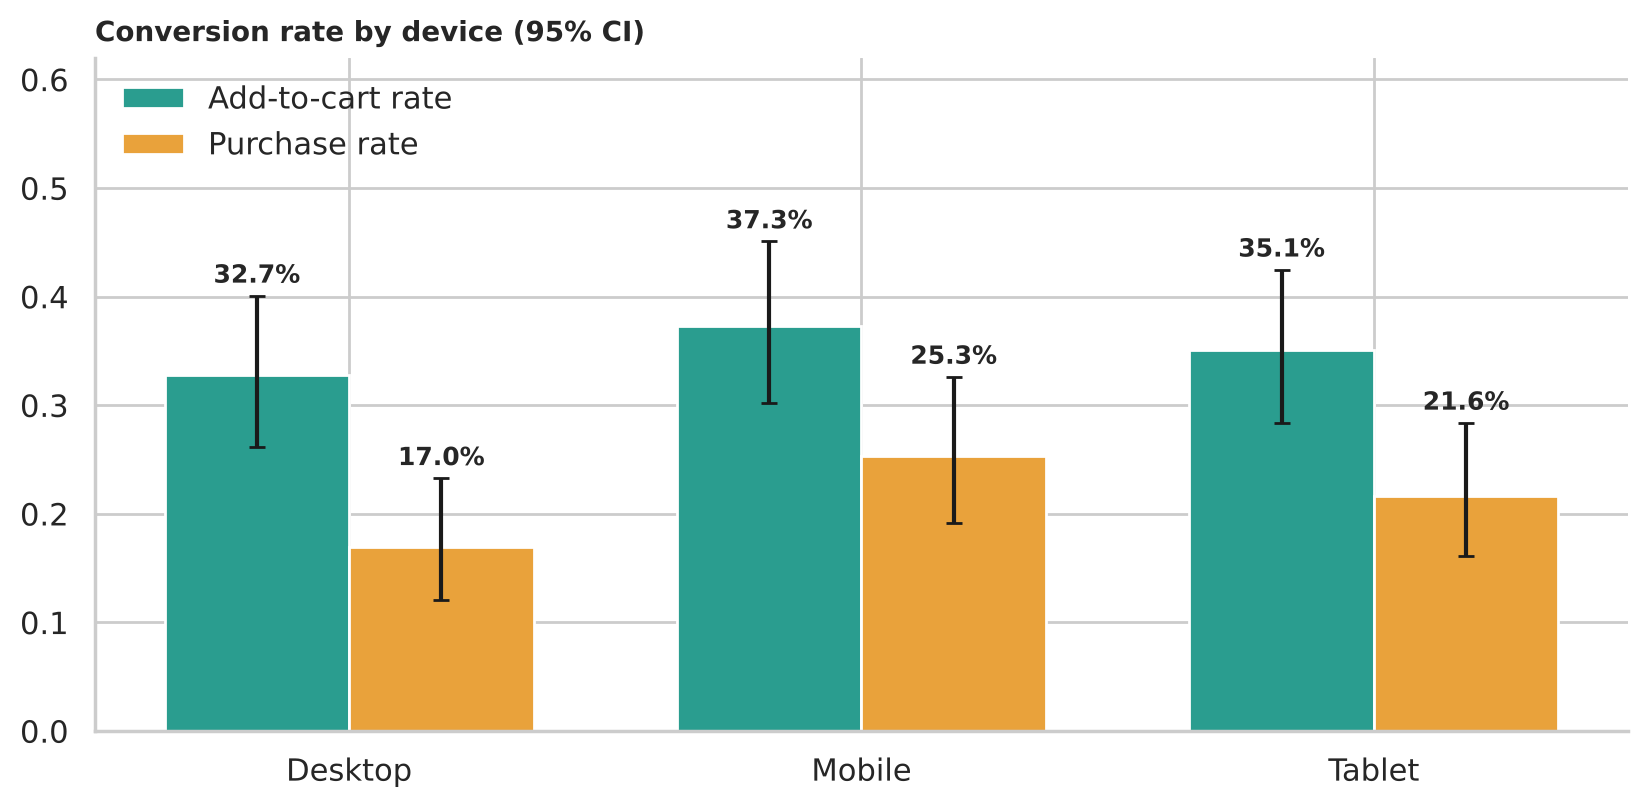

add_to_cart                      purchased                     
                   rate     lo     hi      n      rate     lo     hi      n
device_type                                                                
Desktop           0.327  0.262  0.401  171.0     0.170  0.121  0.233  171.0
Mobile            0.373  0.302  0.451  158.0     0.253  0.192  0.326  158.0
Tablet            0.351  0.283  0.425  171.0     0.216  0.161  0.284  171.0

In [8]:
# Figure 4 - device
dv = pd.concat({c:d.groupby('device_type',observed=True).apply(rate_ci,c) for c in ['add_to_cart','purchased']},axis=1)
R['device_table']=d.groupby('device_type',observed=True).agg(sessions=('session_id','count'),cart_rate=('add_to_cart','mean'),
                 purchase_rate=('purchased','mean'),avg_time=('time_on_page_s','mean')).round(3).reset_index().astype({'device_type':str}).to_dict('records')
fig,ax=plt.subplots(figsize=(8.4,4.2)); x=np.arange(len(dv)); w=.36
for i,(c,l,col) in enumerate([('add_to_cart','Add-to-cart rate',PAL['teal']),('purchased','Purchase rate',PAL['amber'])]):
    r=dv[c]; ax.bar(x+(i-.5)*w,r['rate'],w,yerr=[r['rate']-r['lo'],r['hi']-r['rate']],capsize=3,label=l,color=col)
    for xi,val,h in zip(x+(i-.5)*w,r['rate'],r['hi']): ax.text(xi,h+.012,f'{val:.1%}',ha='center',fontsize=9,fontweight='bold')
ax.set_xticks(x); ax.set_xticklabels(dv.index.astype(str)); ax.set_ylim(0,.62); ax.legend(frameon=False,loc='upper left')
ax.set_title('Conversion rate by device (95% CI)',loc='left',fontweight='bold',fontsize=10)
sns.despine(); plt.tight_layout(); plt.savefig(FIGS+'/fig4_device.png',dpi=170); plt.show(); display(dv.round(3))

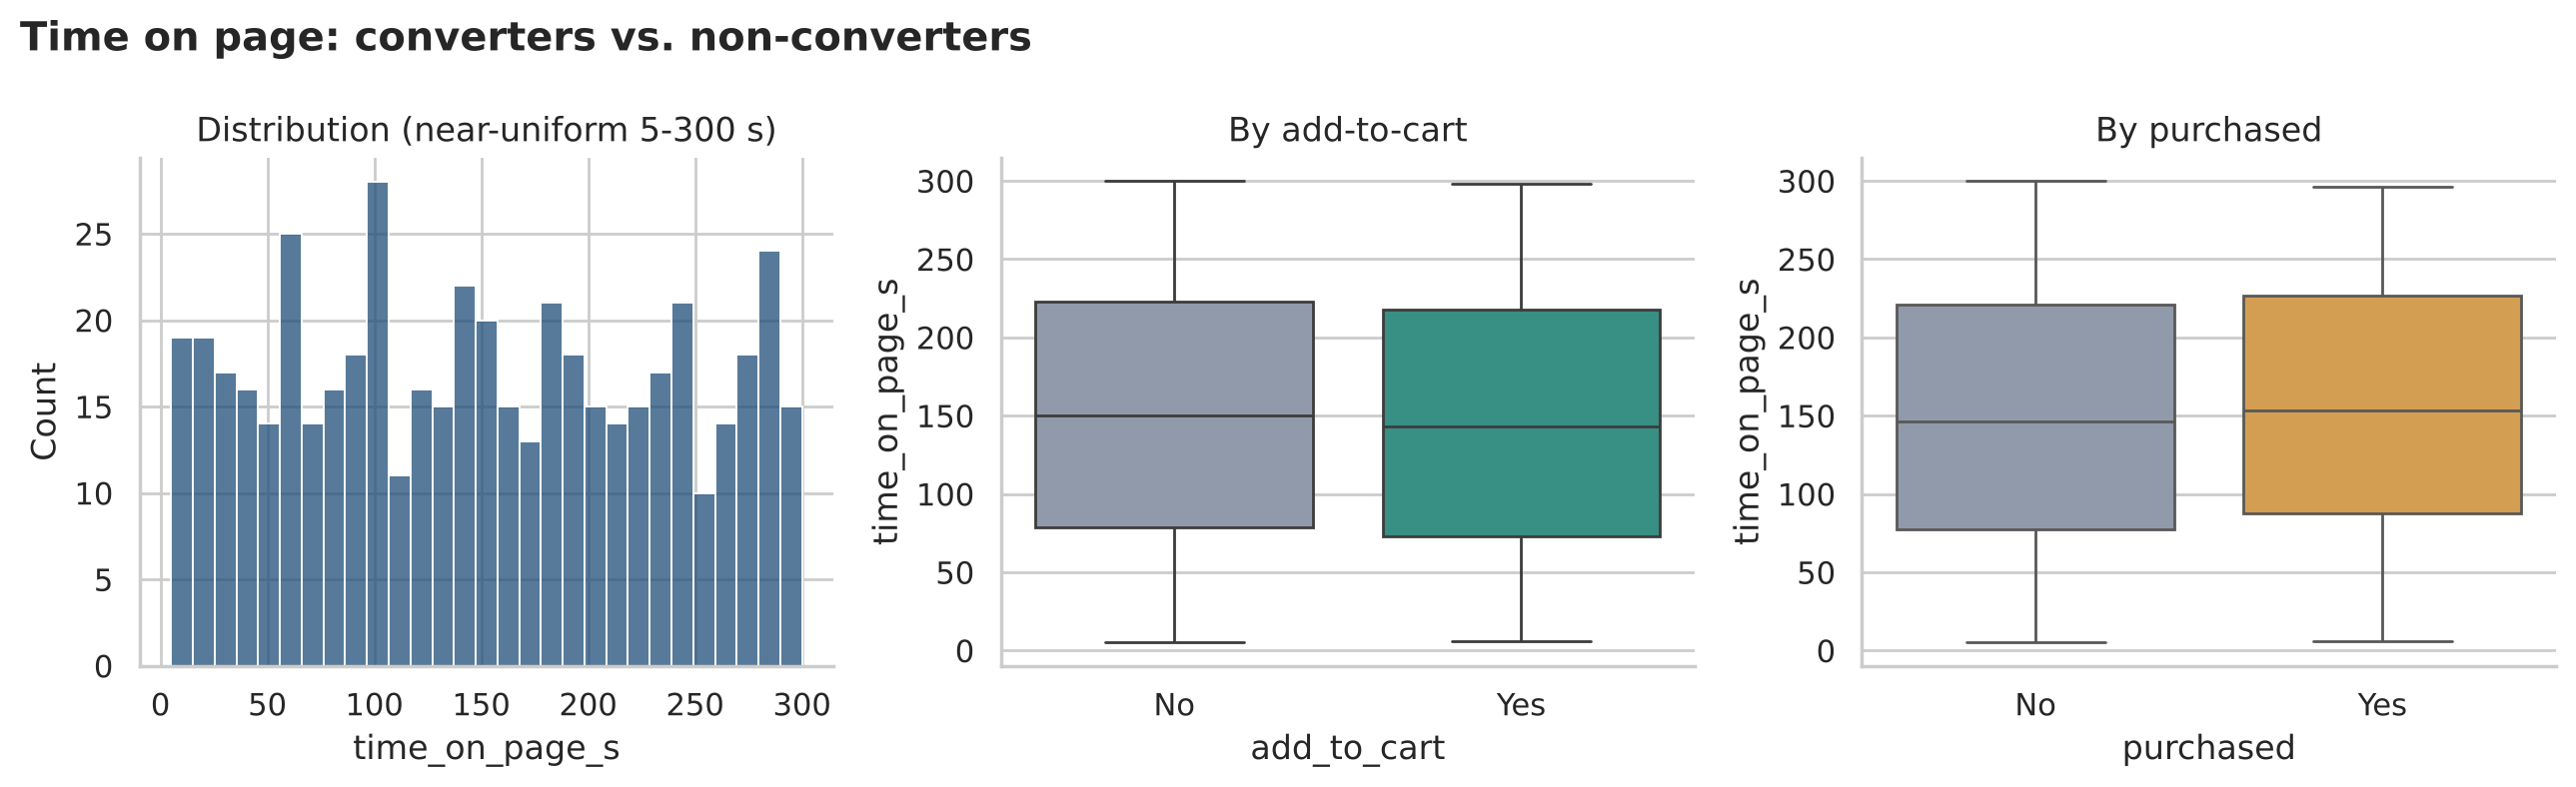

,sessions,cart_rate,purchase_rate
time_bucket,,,
0-60s,100,0.390,0.170
61-120s,100,0.350,0.250
121-180s,104,0.317,0.173
181-240s,98,0.367,0.265
241-300s,98,0.327,0.204


In [9]:
# Figure 5 - time on page
fig,axes=plt.subplots(1,3,figsize=(13,4))
sns.histplot(d.time_on_page_s,bins=29,color=PAL['blue'],ax=axes[0]); axes[0].set_title('Distribution (near-uniform 5-300 s)')
sns.boxplot(data=d,x='add_to_cart',y='time_on_page_s',palette=[PAL['grey'],PAL['teal']],ax=axes[1]); axes[1].set_title('By add-to-cart'); axes[1].set_xticklabels(['No','Yes'])
sns.boxplot(data=d,x='purchased',y='time_on_page_s',palette=[PAL['grey'],PAL['amber']],ax=axes[2]); axes[2].set_title('By purchased'); axes[2].set_xticklabels(['No','Yes'])
fig.suptitle('Time on page: converters vs. non-converters',x=.01,ha='left',fontweight='bold'); sns.despine(); plt.tight_layout(); plt.savefig(FIGS+'/fig5_time.png',dpi=170); plt.show()
tb=d.groupby('time_bucket',observed=True).agg(sessions=('session_id','count'),cart_rate=('add_to_cart','mean'),purchase_rate=('purchased','mean')).round(3)
R['time_table']=tb.reset_index().astype({'time_bucket':str}).to_dict('records'); display(tb)
R.update(time_mean=float(d.time_on_page_s.mean()),time_median=float(d.time_on_page_s.median()),time_std=float(d.time_on_page_s.std()),
         time_mean_cart=float(d[d.add_to_cart==1].time_on_page_s.mean()),time_mean_nocart=float(d[d.add_to_cart==0].time_on_page_s.mean()),
         time_mean_purch=float(d[d.purchased==1].time_on_page_s.mean()),time_mean_nopurch=float(d[d.purchased==0].time_on_page_s.mean()))

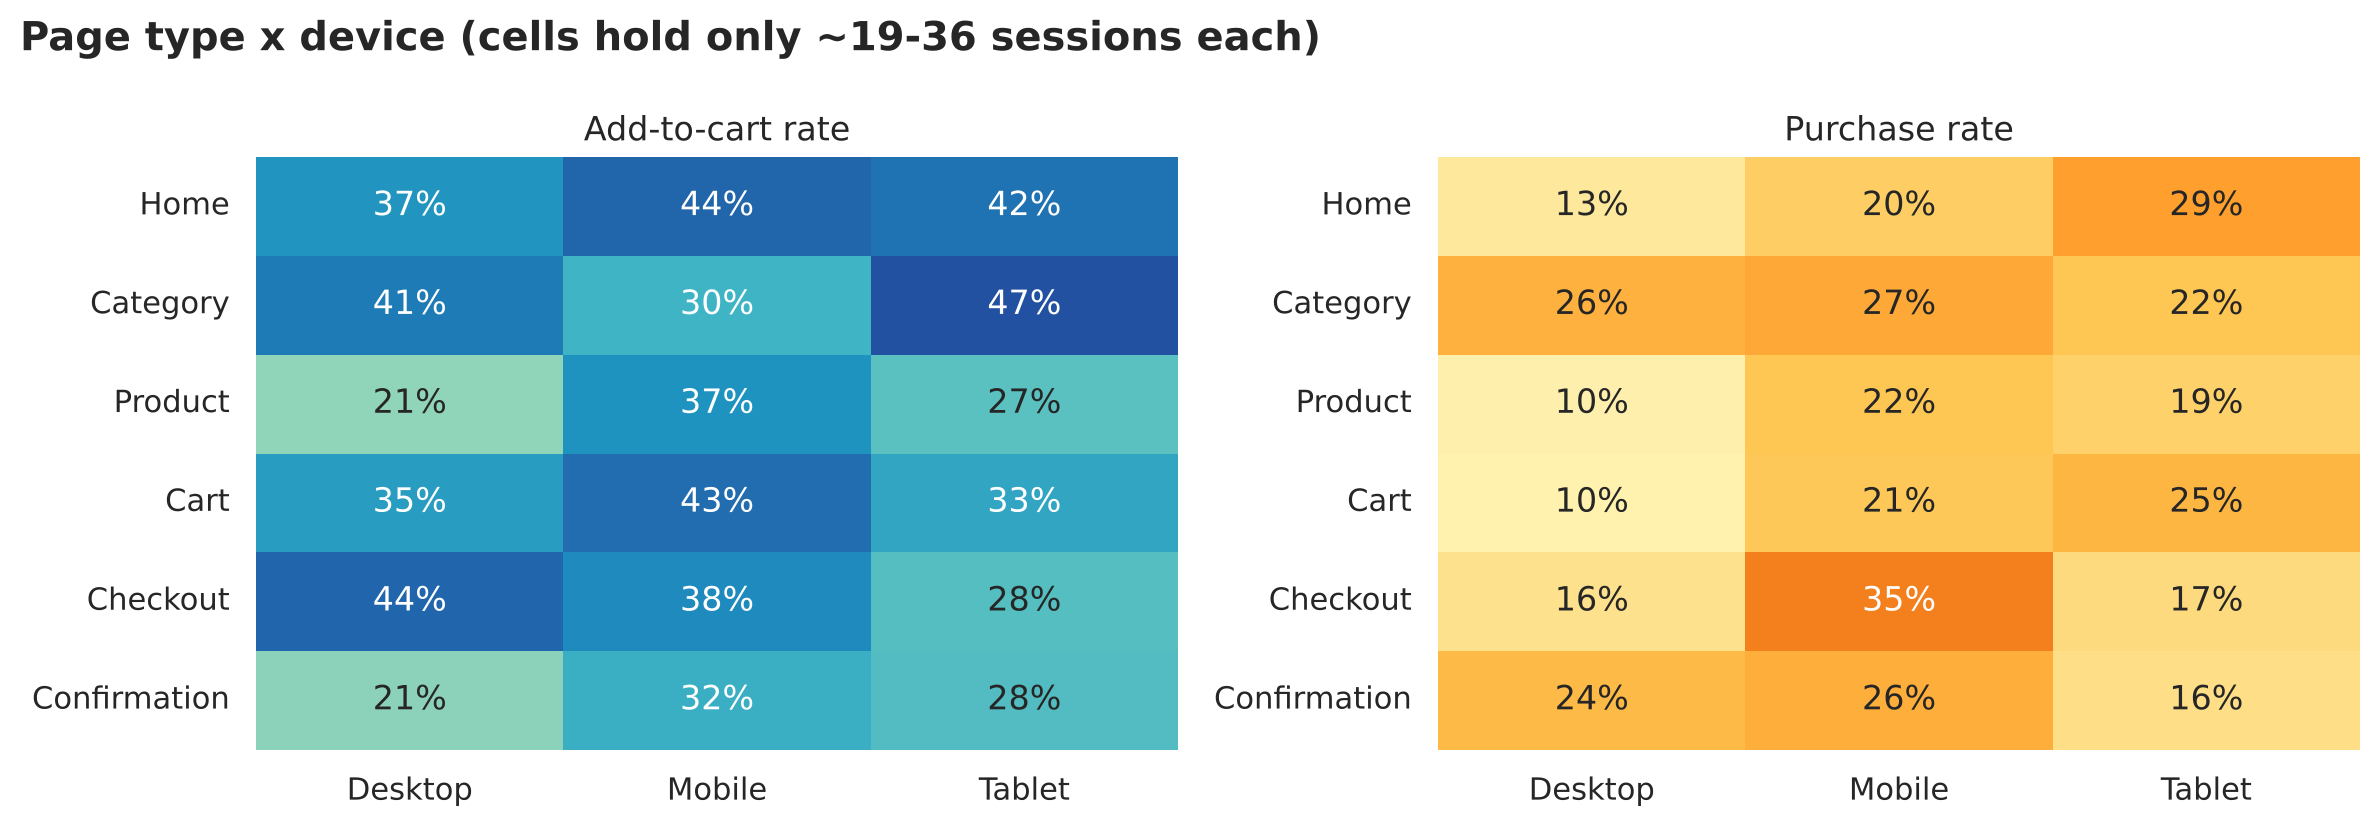

In [10]:
# Figure 6 - page x device heatmaps
fig,axes=plt.subplots(1,2,figsize=(12,4.2))
for ax,(c,t,cm) in zip(axes,[('add_to_cart','Add-to-cart rate','YlGnBu'),('purchased','Purchase rate','YlOrBr')]):
    pv=d.pivot_table(index='page_type',columns='device_type',values=c,aggfunc='mean',observed=True)
    sns.heatmap(pv,annot=True,fmt='.0%',cmap=cm,vmin=0,vmax=.6,cbar=False,ax=ax); ax.set_title(t); ax.set_xlabel(''); ax.set_ylabel('')
fig.suptitle('Page type x device (cells hold only ~19-36 sessions each)',x=.01,ha='left',fontweight='bold'); plt.tight_layout(); plt.savefig(FIGS+'/fig6_heatmap.png',dpi=170); plt.show()

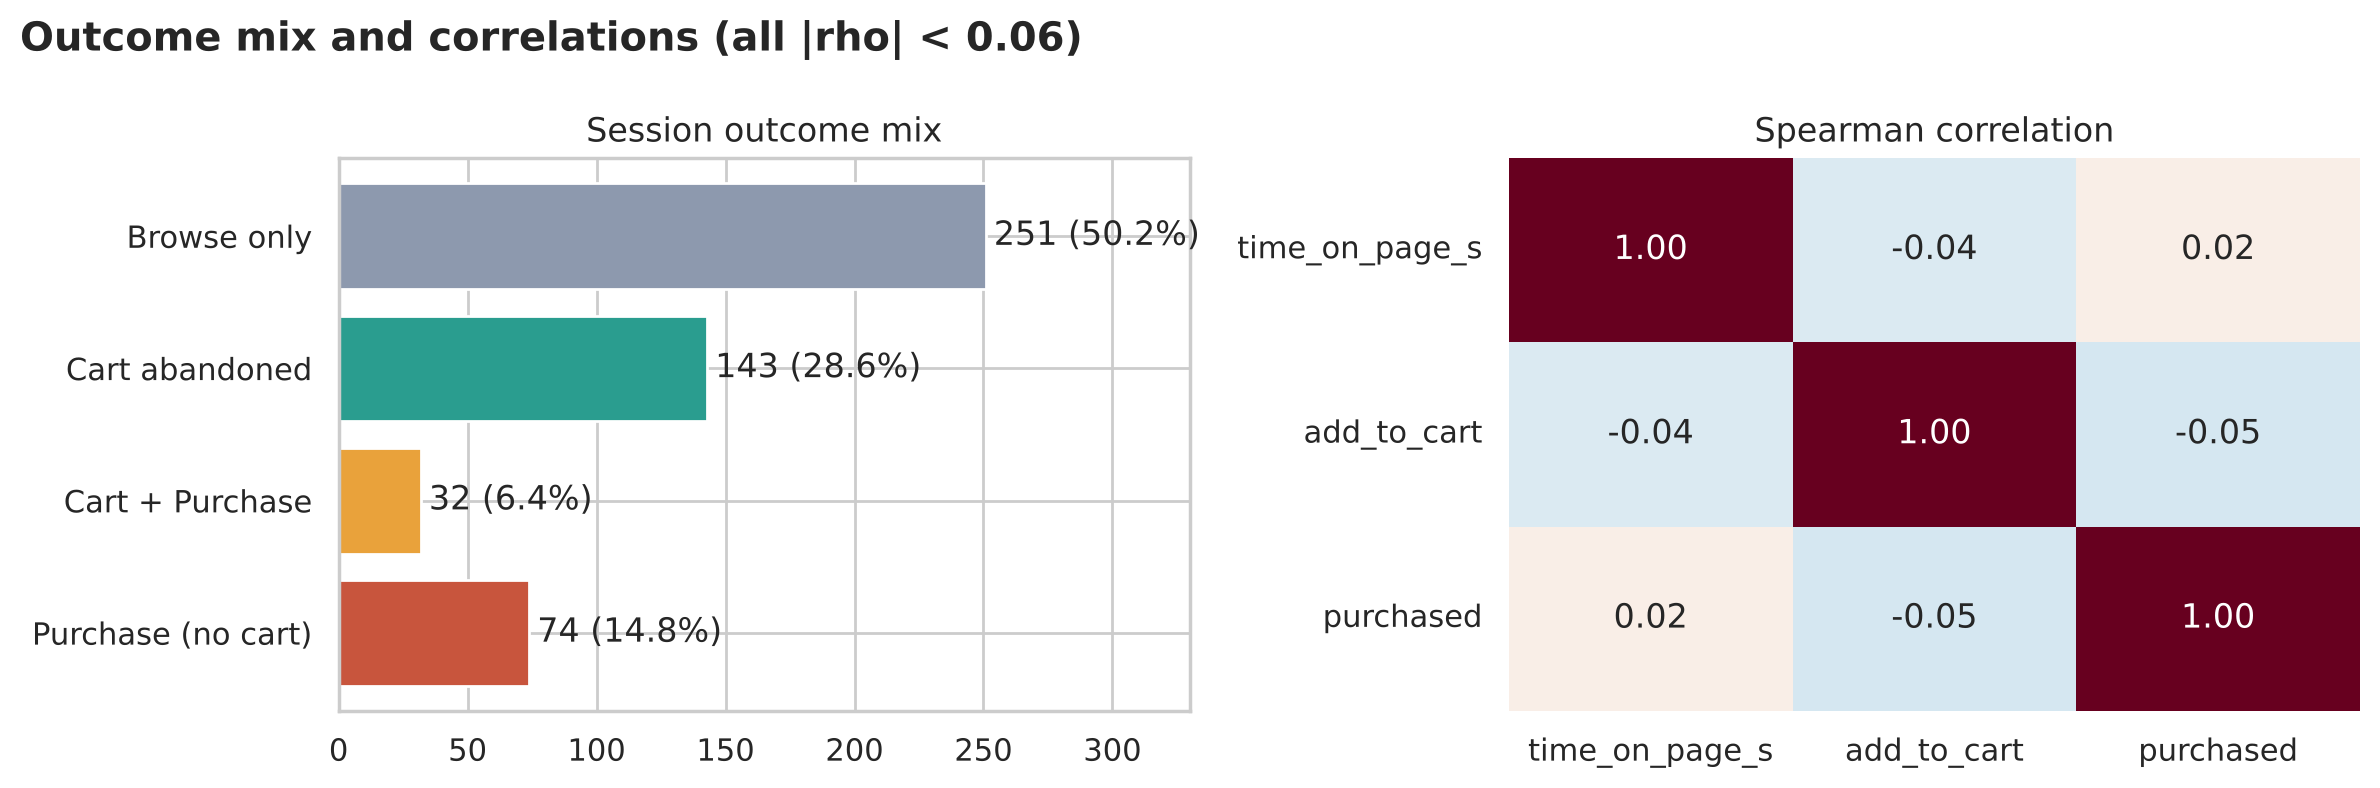

,sessions,purchases
product_id,,
P0040,5,4
P0111,5,3
P0497,4,2
P0017,3,2
P0036,3,2
P0071,3,2
P0407,3,2
P0062,2,2


In [11]:
# Figure 7 - session outcomes + correlation matrix
fig,axes=plt.subplots(1,2,figsize=(12,4))
oc=d.session_outcome.value_counts().reindex(['Browse only','Cart abandoned','Cart + Purchase','Purchase (no cart)'])
axes[0].barh(oc.index,oc.values,color=[PAL['grey'],PAL['teal'],PAL['amber'],PAL['red']]); axes[0].invert_yaxis()
for i,v in enumerate(oc.values): axes[0].text(v+3,i,f'{v} ({v/len(d):.1%})',va='center')
axes[0].set_xlim(0,330); axes[0].set_title('Session outcome mix')
cm=d[['time_on_page_s','add_to_cart','purchased']].corr(method='spearman'); R['corr']=cm.round(3).to_dict()
sns.heatmap(cm,annot=True,fmt='.2f',cmap='RdBu_r',vmin=-.3,vmax=.3,cbar=False,ax=axes[1]); axes[1].set_title('Spearman correlation')
fig.suptitle('Outcome mix and correlations (all |rho| < 0.06)',x=.01,ha='left',fontweight='bold'); plt.tight_layout(); plt.savefig(FIGS+'/fig7_outcomes_corr.png',dpi=170); plt.show()
R['outcomes']=oc.to_dict()
prod=d.groupby('product_id').agg(sessions=('session_id','count'),purchases=('purchased','sum')).sort_values(['purchases','sessions'],ascending=False)
R['top_products']=prod.head(5).reset_index().to_dict('records'); display(prod.head(8))

## 4. Statistical testing
With `n = 500` many apparent gaps in the charts could be noise. We test them: chi-square (+ Cramér's V) for categorical vs binary outcomes, Mann-Whitney U for time vs outcomes, and a Kolmogorov-Smirnov test of whether time-on-page is uniform.

In [12]:
def cramers_v(ct):
    chi2=stats.chi2_contingency(ct,correction=False)[0]; n=ct.values.sum(); return np.sqrt(chi2/(n*(min(ct.shape)-1)))
rows=[]
for col in ['page_type','device_type']:
    for t in ['add_to_cart','purchased']:
        ct=pd.crosstab(d[col],d[t]); chi,p,dof,_=stats.chi2_contingency(ct)
        rows.append([f'{col} vs {t}','Chi-square',f'chi2={chi:.2f}, df={dof}',round(p,3),round(cramers_v(ct),3)])
ct=pd.crosstab(d.add_to_cart,d.purchased); chi,p,_,_=stats.chi2_contingency(ct); rows.append(['add_to_cart vs purchased','Chi-square',f'chi2={chi:.2f}, df=1',round(p,3),round(cramers_v(ct),3)])
for t in ['add_to_cart','purchased']:
    u=stats.mannwhitneyu(d[d[t]==1].time_on_page_s,d[d[t]==0].time_on_page_s); rows.append([f'time_on_page_s vs {t}','Mann-Whitney U',f'U={u.statistic:.0f}',round(u.pvalue,3),'-'])
ks=stats.kstest(d.time_on_page_s,'uniform',args=(5,295)); rows.append(['time_on_page_s ~ Uniform(5,300)','Kolmogorov-Smirnov',f'D={ks.statistic:.3f}',round(ks.pvalue,3),'-'])
tests=pd.DataFrame(rows,columns=['Hypothesis','Test','Statistic','p-value','Effect (Cramer V)']); display(tests)
R['tests']=tests.astype(str).to_dict('records')

# precision: how big a gap could we even detect?
for g in d.device_type.unique(): pass
m=d.groupby('device_type',observed=True).size().min(); p=d.purchased.mean()
R['mde_pp']=float(1.96*np.sqrt(2*p*(1-p)/m)*100); print('Approx. +/- %.1f percentage-point margin when comparing two groups of ~%d sessions' % (R['mde_pp'],m))
bt=stats.binomtest(both,cart,0.68); R['bt_p']=float(bt.pvalue); print('Cart->purchase 18.3%% vs 68%% target: binomial p = %.2e' % bt.pvalue)

,Hypothesis,Test,Statistic,p-value,Effect (Cramer V)
0,page_type vs add_to_cart,Chi-square,"chi2=6.93, df=5",0.226,0.118
1,page_type vs purchased,Chi-square,"chi2=1.86, df=5",0.868,0.061
2,device_type vs add_to_cart,Chi-square,"chi2=0.76, df=2",0.683,0.039
3,device_type vs purchased,Chi-square,"chi2=3.46, df=2",0.177,0.083
4,add_to_cart vs purchased,Chi-square,"chi2=1.11, df=1",0.291,0.052
5,time_on_page_s vs add_to_cart,Mann-Whitney U,U=26955,0.336,-
6,time_on_page_s vs purchased,Mann-Whitney U,U=21442,0.672,-
7,"time_on_page_s ~ Uniform(5,300)",Kolmogorov-Smirnov,D=0.032,0.681,-


Approx. +/- 9.0 percentage-point margin when comparing two groups of ~158 sessions
Cart->purchase 18.3% vs 68% target: binomial p = 9.32e-42


## 5. SQL view (SQLite)
Same questions answered in SQL, as listed in the project's tool stack.

In [13]:
con=sqlite3.connect(':memory:'); d.assign(page_type=d.page_type.astype(str),device_type=d.device_type.astype(str),
    time_bucket=d.time_bucket.astype(str),engagement=d.engagement.astype(str)).to_sql('sessions',con,index=False)
q1='''SELECT device_type, COUNT(*) AS sessions, ROUND(AVG(add_to_cart)*100,1) AS cart_pct, ROUND(AVG(purchased)*100,1) AS purchase_pct
      FROM sessions GROUP BY device_type ORDER BY purchase_pct DESC'''
q2='''SELECT page_type, COUNT(*) AS sessions, SUM(purchased) AS purchases, ROUND(AVG(time_on_page_s),1) AS avg_time_s
      FROM sessions GROUP BY page_type ORDER BY purchases DESC'''
q3='''SELECT session_outcome, COUNT(*) AS sessions, ROUND(100.0*COUNT(*)/(SELECT COUNT(*) FROM sessions),1) AS pct
      FROM sessions GROUP BY session_outcome ORDER BY sessions DESC'''
for q in (q1,q2,q3): display(pd.read_sql(q,con))
R['sql']=[q1,q2,q3]

,device_type,sessions,cart_pct,purchase_pct
0,Mobile,158,37.3,25.3
1,Tablet,171,35.1,21.6
2,Desktop,171,32.7,17.0


,page_type,sessions,purchases,avg_time_s
0,Category,96,24,154.7
1,Checkout,87,19,137.1
2,Home,86,18,149.5
3,Confirmation,77,17,155.3
4,Product,82,14,159.6
5,Cart,72,14,143.2


,session_outcome,sessions,pct
0,Browse only,251,50.2
1,Cart abandoned,143,28.6
2,Purchase (no cart),74,14.8
3,Cart + Purchase,32,6.4


## 6. Predictive check
If purchase behaviour is driven by the recorded features, even a simple model should beat chance. We use 5-fold x 3-repeat stratified cross-validation and report ROC-AUC (0.5 = coin flip).

In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
X=d[['page_type','device_type','time_on_page_s','add_to_cart']].copy(); X['page_type']=X.page_type.astype(str); X['device_type']=X.device_type.astype(str)
res=[]
cv=RepeatedStratifiedKFold(n_splits=5,n_repeats=3,random_state=42)
for target,feats in [('purchased',['page_type','device_type','time_on_page_s','add_to_cart']),('add_to_cart',['page_type','device_type','time_on_page_s'])]:
    pre=ColumnTransformer([('c',OneHotEncoder(),[f for f in feats if f in ('page_type','device_type')]),('n',StandardScaler(),[f for f in feats if f in ('time_on_page_s','add_to_cart')])])
    for name,clf in [('Logistic Regression',LogisticRegression(max_iter=1000)),('Random Forest',RandomForestClassifier(n_estimators=200,max_depth=4,random_state=42))]:
        s=cross_val_score(Pipeline([('p',pre),('m',clf)]),X[feats],d[target],cv=cv,scoring='roc_auc')
        res.append([target,name,round(s.mean(),3),round(s.std(),3)])
mdl=pd.DataFrame(res,columns=['Target','Model','CV ROC-AUC (mean)','Std']); display(mdl); R['models']=mdl.to_dict('records')

,Target,Model,CV ROC-AUC (mean),Std
0,purchased,Logistic Regression,0.473,0.054
1,purchased,Random Forest,0.489,0.054
2,add_to_cart,Logistic Regression,0.520,0.063
3,add_to_cart,Random Forest,0.509,0.039


## 7. Conclusions
* The cart step reproduces the 35% target; the cart→purchase step (18.3%) is far below the 68% target.
* **None** of device, page type, time on page or add-to-cart shows a statistically significant link to purchase; models score AUC ≈ 0.5.
* 74 of 106 purchases carry no add-to-cart, and 60 of 77 `Confirmation` sessions show no purchase - the file behaves like independently assigned flags (no pair of fields is associated), not like a real journey.
* Recommendation: capture **event-level** logs (one row per page view with timestamp, sequence and referrer) and re-run this pipeline.

In [15]:
json.dump(R,open(OUT+'/results.json','w'),indent=2,default=str); print('saved results.json')

saved results.json
